In [ ]:
# PASSWORD VERIFICATION USING DFA

def password_dfa(password):

    # Initial DFA state
    # (length, uppercase, lowercase, digit, special)

    length = 0
    U = 0
    L = 0
    D = 0
    S = 0

    for ch in password:

        # Reject whitespace
        if ch.isspace():
            return False

        # Update DFA state
        if ch.isupper():
            U = 1

        elif ch.islower():
            L = 1

        elif ch.isdigit():
            D = 1

        else:
            S = 1

        # Length is capped at 8
        length = min(length + 1, 8)

    # Final state condition
    if length == 8 and U and L and D and S:
        return True

    return False


# User input
password = input("Enter your password: ")

# DFA validation
if password_dfa(password):
    print("Password ACCEPTED")
else:
    print("Password REJECTED")

Enter your password: 123456
Password REJECTED


In [ ]:
# EMAIL VALIDATION USING DFA

def email_dfa(email):

    state = "q0"

    for ch in email:

        if state == "q0":
            if ch.isalnum():
                state = "q1"
            else:
                return False

        elif state == "q1":
            if ch.isalnum() or ch in "_+:-":
                state = "q1"

            elif ch == ".":
                state = "q2"

            elif ch == "@":
                state = "q3"

            else:
                return False

        elif state == "q2":
            if ch.isalnum():
                state = "q1"
            else:
                return False

        elif state == "q3":
            if ch.isalnum():
                state = "q4"

            else:
                return False

        elif state == "q4":
            if ch.isalnum():
                state = "q4"

            elif ch == "-":
                state = "q5"

            elif ch == ".":
                state = "q6"

            else:
                return False

        elif state == "q5":
            if ch.isalnum():
                state = "q4"
            else:
                return False

        elif state == "q6":
            if ch.isalpha():
                state = "q7"
            else:
                return False

        elif state == "q7":
            if ch.isalpha():
                state = "q8"
            else:
                return False

        elif state == "q8":
            if ch.isalpha():
                state = "q8"
            else:
                return False

    # Final accepting state
    return state == "q8"


# User input
email = input("Enter your email: ")

if email_dfa(email):
    print("Email ACCEPTED")
else:
    print("Email REJECTED")

Enter your email: student@gmail.com
Email ACCEPTED


In [ ]:
# ATM PIN VALIDATION USING DFA

def atm_pin_dfa(pin):

    state = 0

    for ch in pin:

        # Check whether input is a digit
        if ch not in "0123456789":
            state = -1
            break

        # Move to next state
        if state < 4:
            state += 1
        else:
            state = -1
            break

    # Accept only after exactly 4 digits
    return state == 4


# User input
pin = input("Enter your 4-digit ATM PIN: ")

if atm_pin_dfa(pin):
    print("PIN FORMAT ACCEPTED")
else:
    print("PIN FORMAT REJECTED")

Enter your 4-digit ATM PIN: 1234
PIN FORMAT ACCEPTED


In [ ]:
!apt-get -qq install graphviz
!pip -q install graphviz

In [ ]:
# COMBINED AUTOMATA TESTING

print("REAL-TIME APPLICATIONS USING DFA")
print("--------------------------------")

# Password tests
print("\nPASSWORD VALIDATION")

passwords = [
    "Abc@1234",
    "hello123",
    "HELLO@123",
    "Abcdef@1"
]

for p in passwords:
    print(p, ":", "ACCEPTED" if password_dfa(p) else "REJECTED")


# Email tests
print("\nEMAIL VALIDATION")

emails = [
    "student@gmail.com",
    "abc@yahoo.in",
    "studentgmail.com",
    "abc@domain"
]

for e in emails:
    print(e, ":", "ACCEPTED" if email_dfa(e) else "REJECTED")


# ATM PIN tests
print("\nATM PIN VALIDATION")

pins = [
    "1234",
    "123",
    "12345",
    "12ab"
]

for p in pins:
    print(p, ":", "ACCEPTED" if atm_pin_dfa(p) else "REJECTED")

REAL-TIME APPLICATIONS USING DFA
--------------------------------

PASSWORD VALIDATION
Abc@1234 : ACCEPTED
hello123 : REJECTED
HELLO@123 : REJECTED
Abcdef@1 : ACCEPTED

EMAIL VALIDATION
student@gmail.com : ACCEPTED
abc@yahoo.in : ACCEPTED
studentgmail.com : REJECTED
abc@domain : REJECTED

ATM PIN VALIDATION
1234 : ACCEPTED
123 : REJECTED
12345 : REJECTED
12ab : REJECTED


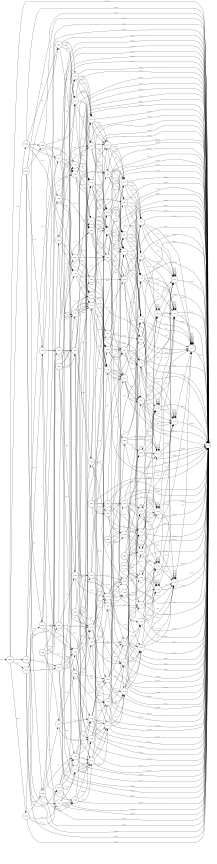

In [ ]:
from graphviz import Digraph

password_graph = Digraph("Password_DFA")

password_graph.attr(rankdir="LR", size="18,12")
password_graph.attr("node", shape="circle", fontsize="8")
password_graph.attr("edge", fontsize="7")

# DFA state: (length, uppercase, lowercase, digit, special)

states = []

for n in range(9):
    for u in range(2):
        for l in range(2):
            for d in range(2):
                for s in range(2):
                    if u + l + d + s <= n:
                        states.append((n, u, l, d, s))


def state_name(state):
    return "s" + "_".join(map(str, state))


# Initial state
start = (0, 0, 0, 0, 0)

password_graph.node("start", shape="point")
password_graph.edge("start", state_name(start))


# Create DFA states
for state in states:

    n, u, l, d, s = state

    label = f"({n},{u}{l}{d}{s})"

    if n == 8 and u == 1 and l == 1 and d == 1 and s == 1:
        password_graph.node(
            state_name(state),
            label,
            shape="doublecircle"
        )
    else:
        password_graph.node(state_name(state), label)


# Input categories
categories = [
    ("Uppercase", 0),
    ("Lowercase", 1),
    ("Digit", 2),
    ("Special", 3)
]


# Transitions
for state in states:

    n, u, l, d, s = state
    flags = [u, l, d, s]

    for label, index in categories:

        new_flags = flags.copy()
        new_flags[index] = 1

        next_state = (
            min(n + 1, 8),
            new_flags[0],
            new_flags[1],
            new_flags[2],
            new_flags[3]
        )

        password_graph.edge(
            state_name(state),
            state_name(next_state),
            label
        )


# Dead state for whitespace
password_graph.node("dead", "Dead")

for state in states:
    password_graph.edge(
        state_name(state),
        "dead",
        "Whitespace"
    )

password_graph.edge("dead", "dead", "Any input")

password_graph

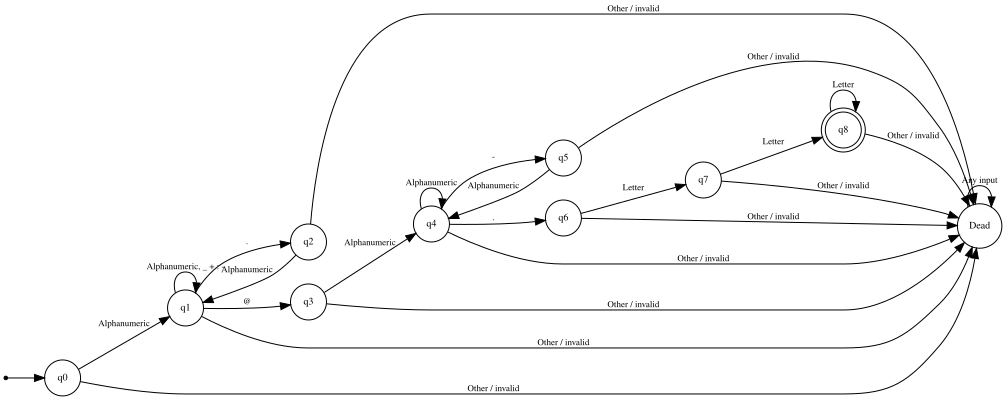

In [ ]:
from graphviz import Digraph

email_graph = Digraph("Email_DFA")

email_graph.attr(rankdir="LR", size="14,8")
email_graph.attr("node", shape="circle", fontsize="10")
email_graph.attr("edge", fontsize="9")

# DFA states
email_graph.node("start", shape="point")
email_graph.node("q0", "q0")
email_graph.node("q1", "q1")
email_graph.node("q2", "q2")
email_graph.node("q3", "q3")
email_graph.node("q4", "q4")
email_graph.node("q5", "q5")
email_graph.node("q6", "q6")
email_graph.node("q7", "q7")
email_graph.node("q8", "q8", shape="doublecircle")
email_graph.node("qD", "Dead", shape="circle")

# Initial transition
email_graph.edge("start", "q0")

# Valid transitions (matching email_dfa in Cell 2)
email_graph.edge("q0", "q1", "Alphanumeric")
email_graph.edge("q1", "q1", "Alphanumeric, _ + : -")
email_graph.edge("q1", "q2", ".")
email_graph.edge("q1", "q3", "@")
email_graph.edge("q2", "q1", "Alphanumeric")
email_graph.edge("q3", "q4", "Alphanumeric")
email_graph.edge("q4", "q4", "Alphanumeric")
email_graph.edge("q4", "q5", "-")
email_graph.edge("q4", "q6", ".")
email_graph.edge("q5", "q4", "Alphanumeric")
email_graph.edge("q6", "q7", "Letter")
email_graph.edge("q7", "q8", "Letter")
email_graph.edge("q8", "q8", "Letter")

# Invalid input transitions
for state in ["q0", "q1", "q2", "q3", "q4",
              "q5", "q6", "q7", "q8"]:
    email_graph.edge(state, "qD", "Other / invalid")

# Dead state loops on any further input
email_graph.edge("qD", "qD", "Any input")

email_graph

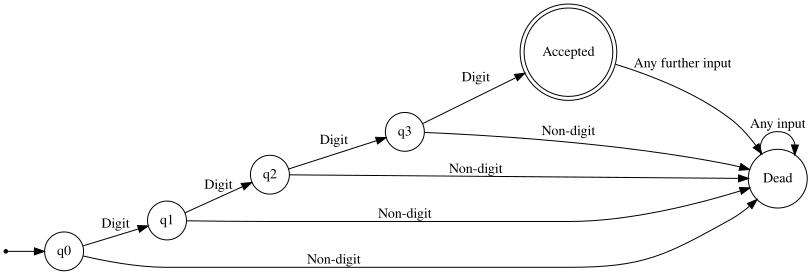

In [ ]:
from graphviz import Digraph

atm = Digraph("ATM_PIN_DFA")
atm.attr(rankdir="LR")

atm.attr("node", shape="circle")

atm.node("start", shape="point")
atm.node("q0", "q0")
atm.node("q1", "q1")
atm.node("q2", "q2")
atm.node("q3", "q3")
atm.node("q4", "Accepted", shape="doublecircle")
atm.node("qD", "Dead")

atm.edge("start", "q0")

atm.edge("q0", "q1", "Digit")
atm.edge("q1", "q2", "Digit")
atm.edge("q2", "q3", "Digit")
atm.edge("q3", "q4", "Digit")

for s in ["q0", "q1", "q2", "q3"]:
    atm.edge(s, "qD", "Non-digit")

atm.edge("q4", "qD", "Any further input")
atm.edge("qD", "qD", "Any input")

atm